# Olist Project - Phase 4: Feature Engineering, Feature Selection and Machine Learning
**Goal:** predict if a delivered order will arrive **late** (1) or **on time** (0), using only information known **when the order is placed**.
Put this notebook in the same folder as `eda_orders_master.csv` (created at the end of the EDA notebook). Run the cells top to bottom.
Your numbers may differ slightly from the notes (different library versions), but the story will be the same.

**Models used (classification):** Dummy baseline, Logistic Regression, Decision Tree, Random Forest, Gradient Boosting.

**Concept box - what is machine learning doing here?**
We show the model many past orders with the answer (late or not). It learns patterns such as "far away + peak month = more risk". Then we hide the answer for some orders (the **test set**) and check how well the model guesses.
Our problem is **binary classification** because the answer has only two values.

## Section 0: Setup

**What:** Import the libraries (all from scikit-learn, no extra installs).
**Why:** pandas/numpy for data, matplotlib/seaborn for charts, scikit-learn for models and metrics.
**Watch out:** scikit-learn must be version 1.2 or newer. If the version printed is older, run `pip install -U scikit-learn` and restart the kernel.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score, average_precision_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve
import joblib

sns.set_style('whitegrid')
print('scikit-learn version:', sklearn.__version__)

scikit-learn version: 1.6.1


## Section 1: Build the ML table (one clean row per order)

**What:** Load the EDA table.
**Why:** It already has one row per delivered order (96,470 rows) with all the columns we need.
**Watch out:** the late rate should be 6.77%, same as in SQL and EDA.

In [2]:
df = pd.read_csv(
    r'C:\Users\Ankur singh patel\OneDrive\Desktop\Brazillian E-Commerce Project\data_clean\eda_orders_master.csv',
    parse_dates=[
        'order_purchase_timestamp',
        'order_delivered_carrier_date',
        'order_delivered_customer_date'
    ]
)

print(df.shape)
print('late %:', round(df['is_late'].mean() * 100, 2))

(96470, 47)
late %: 6.77


**What:** Find the rows with impossible or missing information.
**Why:** A pickup before the purchase, or a delivery before the pickup, is impossible, and a missing distance cannot be used by the model.
**Watch out:** these are real orders. We drop them only for the model, not for the business analysis (same rule as before).

In [3]:
pickup_before_purchase = df['order_delivered_carrier_date'] < df['order_purchase_timestamp']
delivered_before_pickup = df['order_delivered_customer_date'] < df['order_delivered_carrier_date']
no_pickup_date = df['order_delivered_carrier_date'].isnull()
no_distance = df['distance_km'].isnull()

print('Pickup before purchase:', pickup_before_purchase.sum())
print('Delivered before pickup:', delivered_before_pickup.sum())
print('No pickup date:', no_pickup_date.sum())
print('No distance (missing zip):', no_distance.sum())

Pickup before purchase: 165
Delivered before pickup: 23
No pickup date: 1
No distance (missing zip): 486


**What:** Remove those rows.
**Why:** Keeps only orders with reliable dates and a distance.
**Watch out:** a row can have more than one problem, so the total is a little smaller than the sum above (about 674 rows, 0.7%).

In [4]:
bad_rows = pickup_before_purchase | delivered_before_pickup | no_pickup_date | no_distance
print('Rows dropped:', bad_rows.sum())

ml = df[~bad_rows].copy()
print(ml.shape, ' late %:', round(ml['is_late'].mean() * 100, 2))

Rows dropped: 674
(95796, 47)  late %: 6.77


**What:** Fill the few missing values in payment_type (78 orders) and max_installments (1 order).
**Why:** Models cannot work with empty cells.
**Watch out:** these orders have no first-payment record. We label the type 'unknown' and use 1 installment.

In [5]:
print(ml[['payment_type', 'max_installments']].isnull().sum())

ml['payment_type'] = ml['payment_type'].fillna('unknown')
ml['max_installments'] = ml['max_installments'].fillna(1)

payment_type        78
max_installments     1
dtype: int64


**What:** Keep only columns known at purchase time, and check that no leakage column is left.
**Why:** **Data leakage** means using information that does not exist when the order is placed (for example the delivery date). The model would look perfect in testing and fail in real life.
**Watch out:** the printed set of leaked columns must be empty.

In [6]:
keep_cols = ['order_id', 'order_purchase_timestamp', 'purchase_month', 'purchase_weekday', 'purchase_hour',
             'customer_state', 'seller_state', 'same_state', 'distance_km', 'estimated_days',
             'total_price', 'total_freight', 'total_weight_g', 'items', 'sellers', 'category',
             'payment_type', 'max_installments', 'is_late']

leak_cols = ['delivery_days', 'delay_days', 'order_delivered_customer_date', 'order_delivered_carrier_date', 'order_approved_at',
             'purchase_to_approval', 'approval_to_pickup', 'pickup_to_customer', 'seller_late_handover', 'review_score']

print('Leakage columns inside keep_cols:', set(keep_cols) & set(leak_cols))

ml = ml[keep_cols]
ml.shape

Leakage columns inside keep_cols: set()


(95796, 19)

**What:** Save this clean table as the ML table.
**Why:** It is the official input of the model, and you can show it in your project.
**Watch out:** index=False avoids an extra index column.

In [7]:
ml.to_csv('ml_dataset.csv', index=False)
print('Saved ml_dataset.csv', ml.shape)

Saved ml_dataset.csv (95796, 19)


## Section 2: Feature engineering (creating new columns that help the model)

**Concept box - what is feature engineering?**
The model only sees numbers in columns. If we add columns that express a useful idea, the model finds the pattern more easily.
Example: distance alone is useful, but **distance divided by promised days** tells how aggressive the promise is (a far order with a short promise is risky).
We only create columns from information known at purchase time.

**What:** Create ratio columns: price per item, freight-to-price ratio, weight per item, and required speed (km per promised day).
**Why:** They express ideas like "expensive shipping for a cheap product" or "a tight promise for a long distance".
**Watch out:** most orders have 1 item, so price per item is almost the same as total price (we deal with that in feature selection).

In [8]:
ml['price_per_item'] = ml['total_price'] / ml['items']
ml['freight_ratio'] = ml['total_freight'] / ml['total_price']
ml['weight_per_item'] = ml['total_weight_g'] / ml['items']
ml['required_speed'] = ml['distance_km'] / ml['estimated_days']

ml[['price_per_item', 'freight_ratio', 'weight_per_item', 'required_speed']].describe().round(2)

,price_per_item,freight_ratio,weight_per_item,required_speed
count,95796.00,95796.00,95796.00,95796.00
mean,125.31,0.31,2096.70,23.36
std,190.06,0.31,3739.51,20.23
min,0.85,0.00,2.00,0.00
25%,41.90,0.13,300.00,9.24
50%,79.00,0.22,700.00,18.51
75%,139.90,0.38,1800.00,31.06
max,6735.00,21.45,40425.00,257.24


**What:** Create time columns: month of year, peak-season flag (Nov-Dec), weekend flag.
**Why:** EDA showed late deliveries cluster in some periods.
**Watch out:** month_of_year is powerful but needs care. It partly acts as a label for special events (Black Friday 2017, early 2018). We test this honestly in Section 12.

In [9]:
ml['month_of_year'] = ml['order_purchase_timestamp'].dt.month
ml['is_peak_season'] = ml['month_of_year'].isin([11, 12]).astype(int)
ml['is_weekend'] = (ml['purchase_weekday'] >= 5).astype(int)

ml[['month_of_year', 'is_peak_season', 'is_weekend']].head()

,month_of_year,is_peak_season,is_weekend
0,10,0,0
1,7,0,0
2,8,0,0
3,11,1,1
4,2,0,0


**What:** Group the 74 categories into the 15 most common plus 'other'.
**Why:** 74 categories would create 74 columns with very few orders each, which only adds noise.
**Watch out:** the 'other' group mixes small categories, so we lose some detail on purpose.

In [10]:
top_categories = ml['category'].value_counts().head(15).index
ml['category_group'] = ml['category'].where(ml['category'].isin(top_categories), 'other')

print(ml['category_group'].value_counts().head(8))

category_group
other                    20233
bed_bath_table            9128
health_beauty             8562
sports_leisure            7465
computers_accessories     6473
furniture_decor           6177
housewares                5661
watches_gifts             5438
Name: count, dtype: int64


## Section 3: Encoding (turning text columns into numbers)

**Concept box - one-hot encoding.**
Models need numbers, not words. For a column like payment_type (credit_card, boleto, voucher ...) we create one 0/1 column per value: `payment_type_boleto` is 1 when the order was paid by boleto and 0 otherwise.
We drop one value per column (`drop_first=True`) because it can be worked out from the others.

**What:** One-hot encode state, payment type and category group, and join them with the numeric columns.
**Why:** Gives the model a purely numeric table X and the answer y (is_late).
**Watch out:** the number of columns grows to about 85, because there are 27 customer states and 22 seller states.

In [11]:
num_cols = ['estimated_days', 'distance_km', 'total_price', 'total_freight', 'total_weight_g', 'items', 'sellers',
            'max_installments', 'price_per_item', 'freight_ratio', 'weight_per_item', 'required_speed',
            'is_weekend', 'month_of_year', 'is_peak_season', 'purchase_weekday', 'purchase_hour', 'same_state']

dummies = pd.get_dummies(ml[['customer_state', 'seller_state', 'payment_type', 'category_group']], drop_first=True).astype(int)

X = pd.concat([ml[num_cols], dummies], axis=1)
y = ml['is_late']

print(X.shape)

(95796, 84)


## Section 4: Train/test split

**Concept box - why split?**
If we test the model on the same orders it learned from, it can simply memorise them. So we keep 20% of the orders hidden (the **test set**) and only use them at the end to measure real performance.
**Stratified** means both parts keep the same share of late orders (about 6.77%).

**What:** Split 80% train and 20% test, stratified, with a fixed random_state.
**Why:** Fair evaluation, and the same split every time you run the notebook.
**Watch out:** the late % must be almost identical in train and test.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print('Train:', X_train.shape, ' late %:', round(y_train.mean() * 100, 2))
print('Test :', X_test.shape, ' late %:', round(y_test.mean() * 100, 2))

Train: (76636, 84)  late %: 6.77
Test : (19160, 84)  late %: 6.77


## Section 5: Feature selection (keeping only the useful columns)

**Concept box - why select features?**
More columns is not always better. Useless columns add noise, make the model slower and harder to explain, and need more data to collect in real life.
We use the **training set only** for selection (using the test set would be cheating).
Steps: remove very rare columns, remove duplicate columns, rank the rest, keep the best ones.

**What:** Remove one-hot columns that are 1 in fewer than 100 training orders.
**Why:** A column that is almost always 0 gives the model nothing reliable to learn from.
**Watch out:** this removes tiny states or payment types, not important columns.

In [13]:
rare_cols = X_train.columns[X_train.sum() < 100]
print('Rare columns removed:', list(rare_cols))

X_train = X_train.drop(columns=rare_cols)
X_test = X_test.drop(columns=rare_cols)
print(X_train.shape)

Rare columns removed: ['customer_state_AP', 'customer_state_RR', 'seller_state_CE', 'seller_state_MS', 'seller_state_MT', 'seller_state_PA', 'seller_state_PB', 'seller_state_PI', 'seller_state_RN', 'seller_state_RO', 'seller_state_SE', 'payment_type_unknown']
(76636, 72)


**What:** Find pairs of numeric columns that are almost the same (correlation above 0.85).
**Why:** Two near-identical columns carry the same information and can confuse linear models.
**Watch out:** expected pairs: total_price/price_per_item, distance_km/required_speed, total_weight_g/weight_per_item.

In [14]:
corr = X_train[num_cols].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().sort_values(ascending=False)

pairs[pairs > 0.85].round(2)

total_price     price_per_item     0.93
distance_km     required_speed     0.91
total_weight_g  weight_per_item    0.88
dtype: float64

**What:** Drop price_per_item and weight_per_item.
**Why:** For the 90% of orders with 1 item they are the same as total_price and total_weight_g. We keep required_speed even though it is correlated with distance (0.91), because it is the only column that compares distance with the promise.
**Watch out:** this is a judgement decision. We can explain it in the interview.

In [15]:
X_train = X_train.drop(columns=['price_per_item', 'weight_per_item'])
X_test = X_test.drop(columns=['price_per_item', 'weight_per_item'])
print(X_train.shape)

(76636, 70)


**What:** Rank columns with **mutual information** (how much knowing a column reduces uncertainty about is_late), on a 20,000-row sample.
**Why:** A first, model-free view of which columns carry information about lateness.
**Watch out:** it only looks at one column at a time and cannot see combinations. A sample is used to keep it fast.

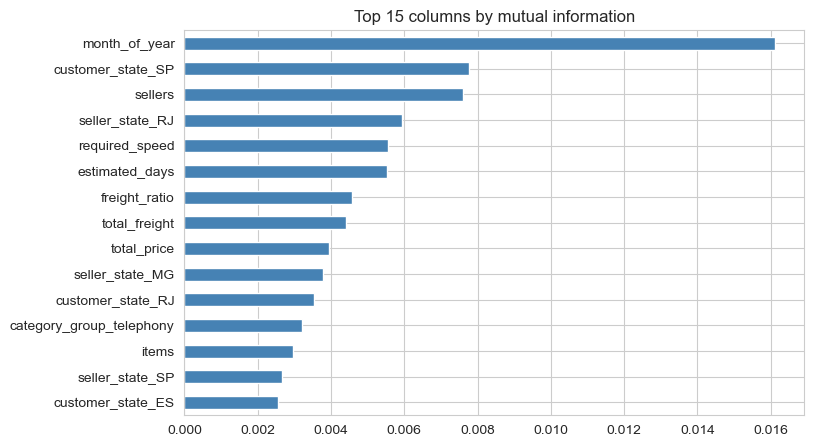

In [16]:
X_sample = X_train.sample(20000, random_state=1)
y_sample = y_train.loc[X_sample.index]

mi = pd.Series(mutual_info_classif(X_sample, y_sample, random_state=42), index=X_sample.columns).sort_values(ascending=False)

mi.head(15).sort_values().plot(kind='barh', figsize=(8, 5), color='steelblue')
plt.title('Top 15 columns by mutual information')
plt.show()

**What:** Rank columns with a quick **Random Forest** (importance = how much each column helps the trees split orders).
**Why:** A model-based ranking that sees combinations of columns.
**Watch out:** importance on training data can favour columns with many distinct values, so we also check it with permutation importance later.

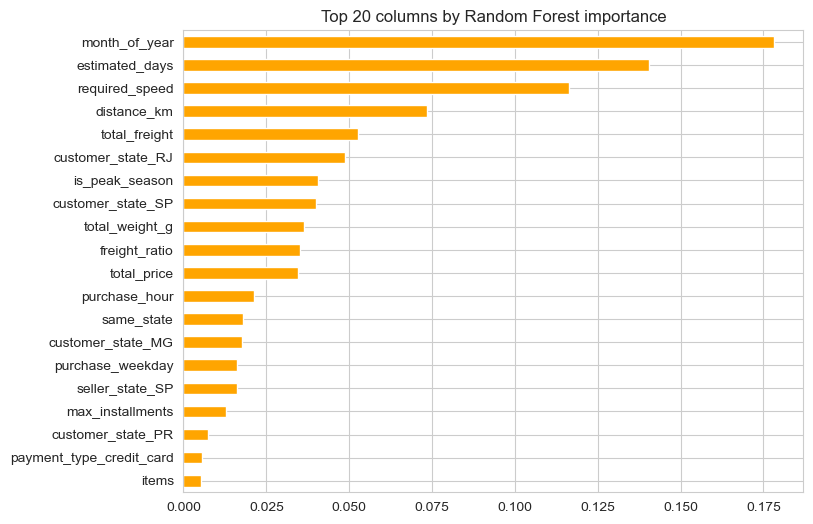

In [17]:
rf_select = RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=20, class_weight='balanced_subsample', n_jobs=-1, random_state=42)
rf_select.fit(X_train, y_train)

importance = pd.Series(rf_select.feature_importances_, index=X_train.columns).sort_values(ascending=False)

importance.head(20).sort_values().plot(kind='barh', figsize=(8, 6), color='orange')
plt.title('Top 20 columns by Random Forest importance')
plt.show()

**What:** Test how many top columns we really need: train the same Gradient Boosting model with all columns, the top 30, top 20 and top 15.
**Why:** We keep the smallest set whose performance is almost the same as using everything.
**Watch out:** PR-AUC is our main metric (explained in Section 7). Expect a small drop for smaller sets.

In [18]:
top30 = importance.head(30).index.tolist()
top20 = importance.head(20).index.tolist()
top15 = importance.head(15).index.tolist()

hgb_all = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, class_weight='balanced', random_state=42).fit(X_train, y_train)
p_all = hgb_all.predict_proba(X_test)[:, 1]
hgb_30 = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, class_weight='balanced', random_state=42).fit(X_train[top30], y_train)
p_30 = hgb_30.predict_proba(X_test[top30])[:, 1]
hgb_20 = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, class_weight='balanced', random_state=42).fit(X_train[top20], y_train)
p_20 = hgb_20.predict_proba(X_test[top20])[:, 1]
hgb_15 = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, class_weight='balanced', random_state=42).fit(X_train[top15], y_train)
p_15 = hgb_15.predict_proba(X_test[top15])[:, 1]

selection_table = pd.DataFrame({
    'columns': [X_train.shape[1], 30, 20, 15],
    'roc_auc': [roc_auc_score(y_test, p_all), roc_auc_score(y_test, p_30), roc_auc_score(y_test, p_20), roc_auc_score(y_test, p_15)],
    'pr_auc': [average_precision_score(y_test, p_all), average_precision_score(y_test, p_30), average_precision_score(y_test, p_20), average_precision_score(y_test, p_15)]
}, index=['all', 'top 30', 'top 20', 'top 15']).round(3)
selection_table

  File "D:\Anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "D:\Anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "D:\Anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "D:\Anaconda3\Lib\subprocess.py", line 1554, in _execute_child
    hp, ht, pi

,columns,roc_auc,pr_auc
all,70,0.785,0.259
top 30,30,0.782,0.254
top 20,20,0.778,0.246
top 15,15,0.772,0.236


**What:** Keep the top 30 columns as the final feature set.
**Why:** Almost the same performance as all columns, with about a third of the inputs, so the model is simpler to explain and to run.
**Watch out:** if the table above shows a big drop for 30 columns, use more columns instead.

In [19]:
selected = top30

X_train_sel = X_train[selected]
X_test_sel = X_test[selected]

print(len(selected), 'selected columns')
print(selected)

30 selected columns
['month_of_year', 'estimated_days', 'required_speed', 'distance_km', 'total_freight', 'customer_state_RJ', 'is_peak_season', 'customer_state_SP', 'total_weight_g', 'freight_ratio', 'total_price', 'purchase_hour', 'same_state', 'customer_state_MG', 'purchase_weekday', 'seller_state_SP', 'max_installments', 'customer_state_PR', 'payment_type_credit_card', 'items', 'seller_state_MG', 'customer_state_BA', 'category_group_other', 'sellers', 'seller_state_RJ', 'is_weekend', 'seller_state_PR', 'seller_state_RS', 'category_group_bed_bath_table', 'category_group_health_beauty']


## Section 6: Baseline - what does a model that learns nothing score?

**What:** A dummy model that always says "on time".
**Why:** Every real model must beat this. It also shows why accuracy is a trap on imbalanced data.
**Watch out:** accuracy is about 93%, but it catches 0 late orders (recall = 0).

In [20]:
results = []

dummy = DummyClassifier(strategy='most_frequent').fit(X_train_sel, y_train)
p_dummy = dummy.predict_proba(X_test_sel)[:, 1]
pred_dummy = dummy.predict(X_test_sel)

results.append({'model': 'Dummy (never late)', 'accuracy': accuracy_score(y_test, pred_dummy), 'recall': recall_score(y_test, pred_dummy),
                'precision': precision_score(y_test, pred_dummy, zero_division=0), 'f1': f1_score(y_test, pred_dummy),
                'roc_auc': roc_auc_score(y_test, p_dummy), 'pr_auc': average_precision_score(y_test, p_dummy)})

print('Accuracy:', round(accuracy_score(y_test, pred_dummy), 3), ' Recall:', recall_score(y_test, pred_dummy))

Accuracy: 0.932  Recall: 0.0


## Section 7: The models

**Concept box - the metrics (read this once).**
- **Recall:** of all late orders, how many did we catch? (we want this high)
- **Precision:** of all orders we flagged as late, how many really were late? (we want this high too)
- **F1:** one number mixing precision and recall.
- **ROC-AUC:** how well the model ranks late orders above on-time ones (0.5 = random guess, 1 = perfect).
- **PR-AUC:** like ROC-AUC but focused on the rare late class. **Our main metric.** A random model scores about 0.068 (the late rate).
- **Class weight 'balanced':** tells the model that a late order is about 14 times more important than an on-time order, because late orders are rare.

**What:** Logistic Regression (a linear model), with scaled inputs.
**Why:** Simple and explainable. Scaling puts all columns on the same range, which this model needs.
**Watch out:** the scaler is fitted on the training data only, then applied to the test data.

In [21]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_sel)
X_test_s = scaler.transform(X_test_sel)

lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42).fit(X_train_s, y_train)
p_lr = lr.predict_proba(X_test_s)[:, 1]
pred_lr = (p_lr >= 0.5).astype(int)

results.append({'model': 'Logistic Regression', 'accuracy': accuracy_score(y_test, pred_lr), 'recall': recall_score(y_test, pred_lr),
                'precision': precision_score(y_test, pred_lr), 'f1': f1_score(y_test, pred_lr),
                'roc_auc': roc_auc_score(y_test, p_lr), 'pr_auc': average_precision_score(y_test, p_lr)})
print(pd.DataFrame(results).round(3).tail(1))

                 model  accuracy  recall  precision     f1  roc_auc  pr_auc
1  Logistic Regression     0.668   0.657      0.126  0.211    0.736   0.192


**What:** A shallow Decision Tree (max depth 6).
**Why:** It learns simple if/else rules, easy to explain. Limiting depth stops it from memorising.
**Watch out:** a single tree is unstable, small data changes can give a different tree.

In [22]:
tree = DecisionTreeClassifier(max_depth=6, min_samples_leaf=100, class_weight='balanced', random_state=42).fit(X_train_sel, y_train)
p_tree = tree.predict_proba(X_test_sel)[:, 1]
pred_tree = (p_tree >= 0.5).astype(int)

results.append({'model': 'Decision Tree', 'accuracy': accuracy_score(y_test, pred_tree), 'recall': recall_score(y_test, pred_tree),
                'precision': precision_score(y_test, pred_tree), 'f1': f1_score(y_test, pred_tree),
                'roc_auc': roc_auc_score(y_test, p_tree), 'pr_auc': average_precision_score(y_test, p_tree)})
print(pd.DataFrame(results).round(3).tail(1))

           model  accuracy  recall  precision     f1  roc_auc  pr_auc
2  Decision Tree     0.728   0.648       0.15  0.244    0.745   0.195


**What:** Random Forest (100 trees voting).
**Why:** Many different trees averaged together are more stable and can capture combinations such as region x distance.
**Watch out:** slower than the models above (about 15 to 30 seconds).

In [23]:
rf = RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=20, class_weight='balanced_subsample', n_jobs=-1, random_state=42).fit(X_train_sel, y_train)
p_rf = rf.predict_proba(X_test_sel)[:, 1]
pred_rf = (p_rf >= 0.5).astype(int)

results.append({'model': 'Random Forest', 'accuracy': accuracy_score(y_test, pred_rf), 'recall': recall_score(y_test, pred_rf),
                'precision': precision_score(y_test, pred_rf), 'f1': f1_score(y_test, pred_rf),
                'roc_auc': roc_auc_score(y_test, p_rf), 'pr_auc': average_precision_score(y_test, p_rf)})
print(pd.DataFrame(results).round(3).tail(1))

           model  accuracy  recall  precision     f1  roc_auc  pr_auc
3  Random Forest     0.818   0.544      0.196  0.288    0.779   0.251


**What:** Gradient Boosting (HistGradientBoosting).
**Why:** Trees are built one after another and each tries to fix the mistakes of the previous ones. Usually the strongest model on tables like ours.
**Watch out:** it has more settings (hyperparameters), which we tune in Section 9.

In [24]:
hgb = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, class_weight='balanced', random_state=42).fit(X_train_sel, y_train)
p_hgb = hgb.predict_proba(X_test_sel)[:, 1]
pred_hgb = (p_hgb >= 0.5).astype(int)

results.append({'model': 'Gradient Boosting', 'accuracy': accuracy_score(y_test, pred_hgb), 'recall': recall_score(y_test, pred_hgb),
                'precision': precision_score(y_test, pred_hgb), 'f1': f1_score(y_test, pred_hgb),
                'roc_auc': roc_auc_score(y_test, p_hgb), 'pr_auc': average_precision_score(y_test, p_hgb)})
print(pd.DataFrame(results).round(3).tail(1))

               model  accuracy  recall  precision     f1  roc_auc  pr_auc
4  Gradient Boosting     0.749   0.672      0.166  0.266    0.782   0.254


**What:** Put all results in one table (threshold 0.5).
**Why:** To compare the models side by side.
**Watch out:** ignore accuracy (the dummy has the best one). Compare PR-AUC, ROC-AUC and recall/precision.

In [25]:
results_df = pd.DataFrame(results).set_index('model').round(3)
results_df

,accuracy,recall,precision,f1,roc_auc,pr_auc
model,,,,,,
Dummy (never late),0.932,0.000,0.000,0.000,0.500,0.068
Logistic Regression,0.668,0.657,0.126,0.211,0.736,0.192
Decision Tree,0.728,0.648,0.150,0.244,0.745,0.195
Random Forest,0.818,0.544,0.196,0.288,0.779,0.251
Gradient Boosting,0.749,0.672,0.166,0.266,0.782,0.254


## Section 8: Looking at the results

**What:** ROC curves and precision-recall curves of all models.
**Why:** A curve shows performance at every possible threshold, not only at 0.5. The higher curve is the better model.
**Watch out:** on the PR chart the dotted line is the late rate (6.8%), which is what a random model scores.

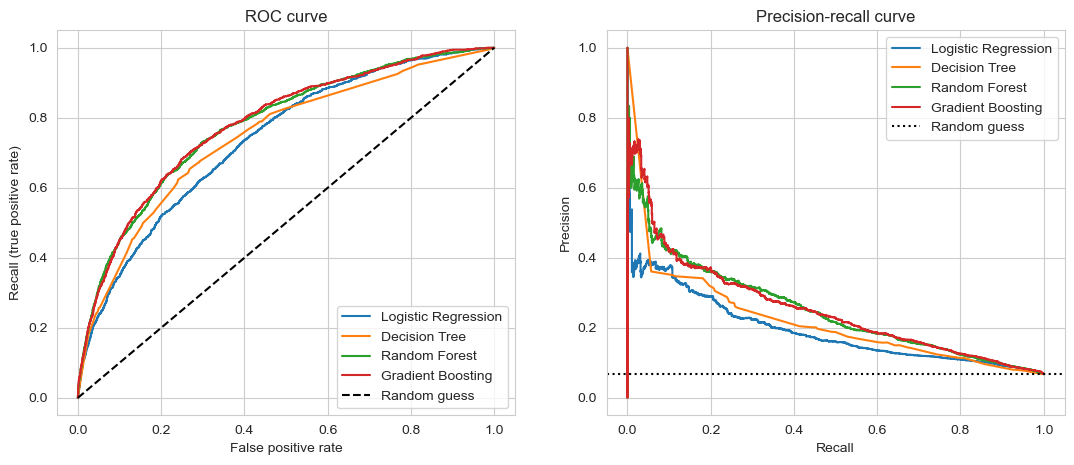

In [26]:
fpr_lr, tpr_lr, _ = roc_curve(y_test, p_lr)
fpr_tree, tpr_tree, _ = roc_curve(y_test, p_tree)
fpr_rf, tpr_rf, _ = roc_curve(y_test, p_rf)
fpr_hgb, tpr_hgb, _ = roc_curve(y_test, p_hgb)

pr_lr, rc_lr, _ = precision_recall_curve(y_test, p_lr)
pr_tree, rc_tree, _ = precision_recall_curve(y_test, p_tree)
pr_rf, rc_rf, _ = precision_recall_curve(y_test, p_rf)
pr_hgb, rc_hgb, _ = precision_recall_curve(y_test, p_hgb)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].plot(fpr_lr, tpr_lr, label='Logistic Regression')
ax[0].plot(fpr_tree, tpr_tree, label='Decision Tree')
ax[0].plot(fpr_rf, tpr_rf, label='Random Forest')
ax[0].plot(fpr_hgb, tpr_hgb, label='Gradient Boosting')
ax[0].plot([0, 1], [0, 1], 'k--', label='Random guess')
ax[0].set_title('ROC curve')
ax[0].set_xlabel('False positive rate')
ax[0].set_ylabel('Recall (true positive rate)')
ax[0].legend()
ax[1].plot(rc_lr, pr_lr, label='Logistic Regression')
ax[1].plot(rc_tree, pr_tree, label='Decision Tree')
ax[1].plot(rc_rf, pr_rf, label='Random Forest')
ax[1].plot(rc_hgb, pr_hgb, label='Gradient Boosting')
ax[1].axhline(y_test.mean(), color='k', linestyle=':', label='Random guess')
ax[1].set_title('Precision-recall curve')
ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precision')
ax[1].legend()
plt.show()

**What:** Confusion matrix of Gradient Boosting at threshold 0.5.
**Why:** Shows the four outcomes: late orders caught, late orders missed, false alarms, correct on-time.
**Watch out:** with 6.8% late orders, even a good model makes many false alarms. That is normal for rare events.

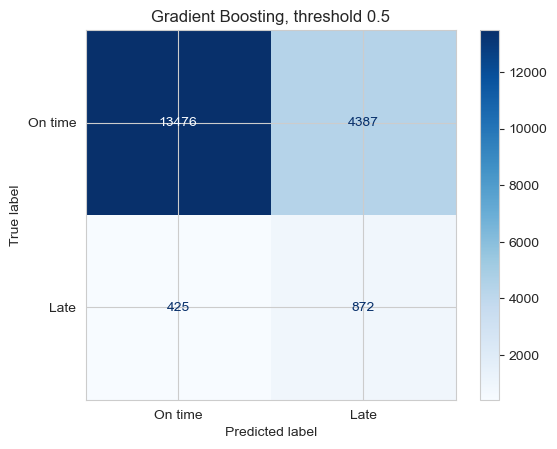

Late orders caught: 872  missed: 425  false alarms: 4387  correct on-time: 13476


In [27]:
ConfusionMatrixDisplay.from_predictions(y_test, pred_hgb, display_labels=['On time', 'Late'], cmap='Blues')
plt.title('Gradient Boosting, threshold 0.5')
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, pred_hgb).ravel()
print('Late orders caught:', tp, ' missed:', fn, ' false alarms:', fp, ' correct on-time:', tn)

**What:** Coefficients of the Logistic Regression (the 8 columns pushing most toward late and most toward on-time).
**Why:** The easiest way to explain a model: a positive number raises the late risk, a negative number lowers it.
**Watch out:** columns were scaled, so coefficients are comparable in size. The sign shows the direction.

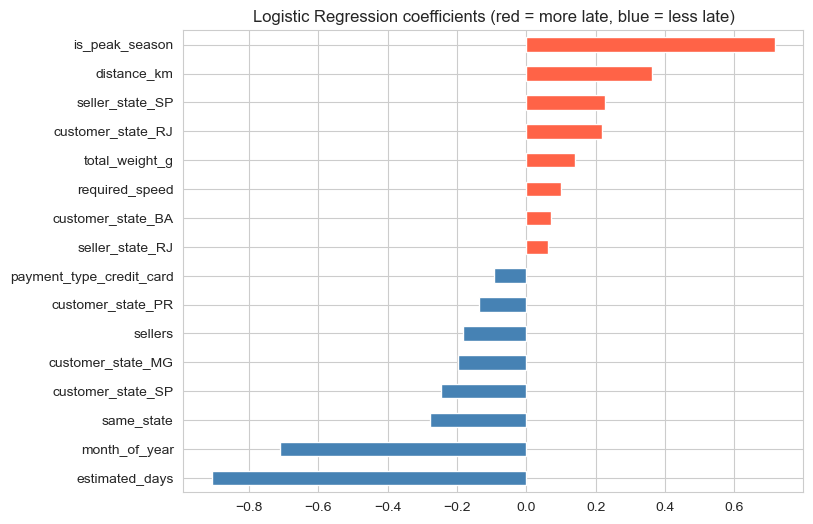

In [28]:
coef = pd.Series(lr.coef_[0], index=selected).sort_values()
coef_plot = pd.concat([coef.head(8), coef.tail(8)])

coef_plot.plot(kind='barh', figsize=(8, 6), color=np.where(coef_plot > 0, 'tomato', 'steelblue'))
plt.title('Logistic Regression coefficients (red = more late, blue = less late)')
plt.show()

**What:** Print the rules of a very small Decision Tree (depth 3).
**Why:** Shows in plain if/else form how a tree thinks. Good for explaining in an interview.
**Watch out:** this small tree is only for explanation, it is not the model we evaluate.

In [29]:
small_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=200, class_weight='balanced', random_state=42).fit(X_train_sel, y_train)
print(export_text(small_tree, feature_names=selected))

|--- month_of_year <= 3.50
|   |--- required_speed <= 13.25
|   |   |--- required_speed <= 7.45
|   |   |   |--- class: 0
|   |   |--- required_speed >  7.45
|   |   |   |--- class: 1
|   |--- required_speed >  13.25
|   |   |--- month_of_year <= 1.50
|   |   |   |--- class: 0
|   |   |--- month_of_year >  1.50
|   |   |   |--- class: 1
|--- month_of_year >  3.50
|   |--- month_of_year <= 10.50
|   |   |--- required_speed <= 47.73
|   |   |   |--- class: 0
|   |   |--- required_speed >  47.73
|   |   |   |--- class: 1
|   |--- month_of_year >  10.50
|   |   |--- customer_state_RJ <= 0.50
|   |   |   |--- class: 1
|   |   |--- customer_state_RJ >  0.50
|   |   |   |--- class: 1



## Section 9: Cross-validation and tuning

**Concept box - cross-validation.**
One train/test split can be lucky or unlucky. In 5-fold cross-validation we split the training data into 5 parts and train 5 times, each time using a different part as the test. If the 5 scores are similar, the model is stable.

**What:** 5-fold cross-validation of Logistic Regression and Random Forest on the training data.
**Why:** Checks that the scores are stable and not a lucky split.
**Watch out:** for Logistic Regression the scaler was fitted on all training data (a tiny simplification).

In [30]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_lr = cross_validate(LogisticRegression(class_weight='balanced', max_iter=1000), X_train_s, y_train, cv=cv, scoring=['roc_auc', 'average_precision'])
print('Logistic Regression  ROC-AUC:', cv_lr['test_roc_auc'].round(3), ' mean:', cv_lr['test_roc_auc'].mean().round(3))
print('Logistic Regression  PR-AUC :', cv_lr['test_average_precision'].round(3), ' mean:', cv_lr['test_average_precision'].mean().round(3))

cv_rf = cross_validate(RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=20, class_weight='balanced_subsample', n_jobs=-1, random_state=42), X_train_sel, y_train, cv=cv, scoring=['roc_auc', 'average_precision'])
print('Random Forest        ROC-AUC:', cv_rf['test_roc_auc'].round(3), ' mean:', cv_rf['test_roc_auc'].mean().round(3))
print('Random Forest        PR-AUC :', cv_rf['test_average_precision'].round(3), ' mean:', cv_rf['test_average_precision'].mean().round(3))

Logistic Regression  ROC-AUC: [0.75  0.741 0.743 0.729 0.758]  mean: 0.744
Logistic Regression  PR-AUC : [0.192 0.198 0.19  0.182 0.207]  mean: 0.194
Random Forest        ROC-AUC: [0.777 0.772 0.783 0.768 0.784]  mean: 0.777
Random Forest        PR-AUC : [0.259 0.245 0.251 0.222 0.264]  mean: 0.248


**What:** 5-fold cross-validation of Gradient Boosting.
**Why:** Same stability check for the best model.
**Watch out:** the 5 scores should be close to each other (small spread).

In [31]:
cv_hgb = cross_validate(HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, class_weight='balanced', random_state=42), X_train_sel, y_train, cv=cv, scoring=['roc_auc', 'average_precision'])
print('Gradient Boosting ROC-AUC:', cv_hgb['test_roc_auc'].round(3), ' mean:', cv_hgb['test_roc_auc'].mean().round(3))
print('Gradient Boosting PR-AUC :', cv_hgb['test_average_precision'].round(3), ' mean:', cv_hgb['test_average_precision'].mean().round(3))

Gradient Boosting ROC-AUC: [0.78  0.778 0.785 0.771 0.788]  mean: 0.781
Gradient Boosting PR-AUC : [0.255 0.248 0.245 0.222 0.259]  mean: 0.246


**Concept box - hyperparameter tuning.**
Every model has settings (learning rate, number of trees, tree size ...). Instead of guessing, we try 8 random combinations, score each with 3-fold cross-validation on the training data, and keep the best.
We tune for PR-AUC because it focuses on the rare late class.

**What:** Random search over Gradient Boosting settings.
**Why:** The default settings are rarely the best.
**Watch out:** takes about 1 to 3 minutes. The test set is NOT used here (so the final test stays fair).

In [32]:
param_options = {
    'learning_rate': [0.03, 0.05, 0.1],
    'max_iter': [100, 200, 300],
    'max_leaf_nodes': [15, 31, 63],
    'min_samples_leaf': [20, 50, 100],
    'l2_regularization': [0, 1, 10]
}

search = RandomizedSearchCV(HistGradientBoostingClassifier(class_weight='balanced', random_state=42), param_options,
                            n_iter=8, cv=3, scoring='average_precision', random_state=42, n_jobs=1)
search.fit(X_train_sel, y_train)

print('Best settings:', search.best_params_)
print('Best cross-validated PR-AUC:', round(search.best_score_, 3))

Best settings: {'min_samples_leaf': 100, 'max_leaf_nodes': 63, 'max_iter': 300, 'learning_rate': 0.05, 'l2_regularization': 10}
Best cross-validated PR-AUC: 0.246


**What:** Evaluate the tuned model on the test set and add it to the results table.
**Why:** The one final check on data the model never saw.
**Watch out:** tuning often gives only a small gain. That is normal.

In [33]:
final = search.best_estimator_
p_final = final.predict_proba(X_test_sel)[:, 1]
pred_final = (p_final >= 0.5).astype(int)

results.append({'model': 'Gradient Boosting (tuned)', 'accuracy': accuracy_score(y_test, pred_final), 'recall': recall_score(y_test, pred_final),
                'precision': precision_score(y_test, pred_final), 'f1': f1_score(y_test, pred_final),
                'roc_auc': roc_auc_score(y_test, p_final), 'pr_auc': average_precision_score(y_test, p_final)})

results_df = pd.DataFrame(results).set_index('model').round(3)
results_df

,accuracy,recall,precision,f1,roc_auc,pr_auc
model,,,,,,
Dummy (never late),0.932,0.000,0.000,0.000,0.500,0.068
Logistic Regression,0.668,0.657,0.126,0.211,0.736,0.192
Decision Tree,0.728,0.648,0.150,0.244,0.745,0.195
Random Forest,0.818,0.544,0.196,0.288,0.779,0.251
Gradient Boosting,0.749,0.672,0.166,0.266,0.782,0.254
Gradient Boosting (tuned),0.756,0.677,0.171,0.273,0.783,0.258


## Section 10: Choosing the threshold

**Concept box - threshold.**
The model gives each order a risk score between 0 and 1. We must pick a cut-off: orders above it are flagged as "likely late".
A low cut-off catches more late orders but raises more false alarms. A high cut-off gives fewer, more accurate alerts but misses more late orders.
The right choice depends on the business: how costly is a missed late order compared with a false alarm?

**What:** Show recall, precision and number of alerts for several thresholds on the test set.
**Why:** Makes the trade-off visible.
**Watch out:** this is only for looking. We do not pick the threshold on the test set.

In [34]:
th = np.array([0.3, 0.4, 0.5, 0.6, 0.7, 0.8])
flagged = p_final.reshape(-1, 1) >= th
alerts = flagged.sum(axis=0)
caught = (flagged & (y_test.values.reshape(-1, 1) == 1)).sum(axis=0)

threshold_table = pd.DataFrame({'threshold': th, 'alerts': alerts, 'late_caught': caught})
threshold_table['recall'] = (caught / y_test.sum()).round(3)
threshold_table['precision'] = (caught / alerts).round(3)
threshold_table

,threshold,alerts,late_caught,recall,precision
0,0.3,10410,1121,0.864,0.108
1,0.4,7328,992,0.765,0.135
2,0.5,5141,878,0.677,0.171
3,0.6,3395,724,0.558,0.213
4,0.7,1909,508,0.392,0.266
5,0.8,683,252,0.194,0.369


**What:** Choose the threshold using cross-validated predictions on the TRAINING data: the highest threshold that still catches at least 60% of late orders.
**Why:** Business rule: "catch 6 in 10 late orders, with as few false alarms as possible". Choosing on training data keeps the test set clean.
**Watch out:** the rule (60%) is a business choice. Change it and the threshold changes.

In [35]:
p_cv = cross_val_predict(final, X_train_sel, y_train, cv=3, method='predict_proba')[:, 1]

prec_cv, rec_cv, thr_cv = precision_recall_curve(y_train, p_cv)
ok = rec_cv[:-1] >= 0.60
chosen_threshold = thr_cv[ok].max()
print('Chosen threshold:', round(chosen_threshold, 3))

Chosen threshold: 0.544


**What:** Apply the chosen threshold to the test set and show the confusion matrix.
**Why:** The final, honest performance of the model with a business-based cut-off.
**Watch out:** precision stays low because late orders are rare. The model is a risk ranker, not a crystal ball.

Recall   : 0.626
Precision: 0.188
Orders flagged: 4313 of 19160 ( 22.5 %)


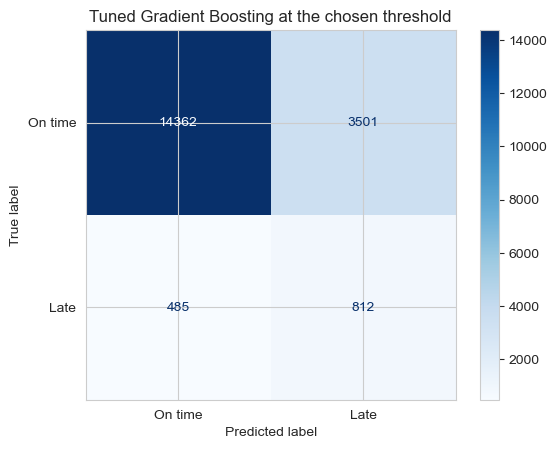

In [36]:
pred_chosen = (p_final >= chosen_threshold).astype(int)

print('Recall   :', round(recall_score(y_test, pred_chosen), 3))
print('Precision:', round(precision_score(y_test, pred_chosen), 3))
print('Orders flagged:', pred_chosen.sum(), 'of', len(y_test), '(', round(pred_chosen.mean() * 100, 1), '%)')

ConfusionMatrixDisplay.from_predictions(y_test, pred_chosen, display_labels=['On time', 'Late'], cmap='Blues')
plt.title('Tuned Gradient Boosting at the chosen threshold')
plt.show()

## Section 11: Which features drive the predictions?

**What:** Permutation importance of the final model: shuffle one column at a time and see how much the ROC-AUC drops.
**Why:** A big drop means the model relies on that column. It is more reliable than the tree-based importance.
**Watch out:** uses a sample of 8,000 test orders to stay fast.

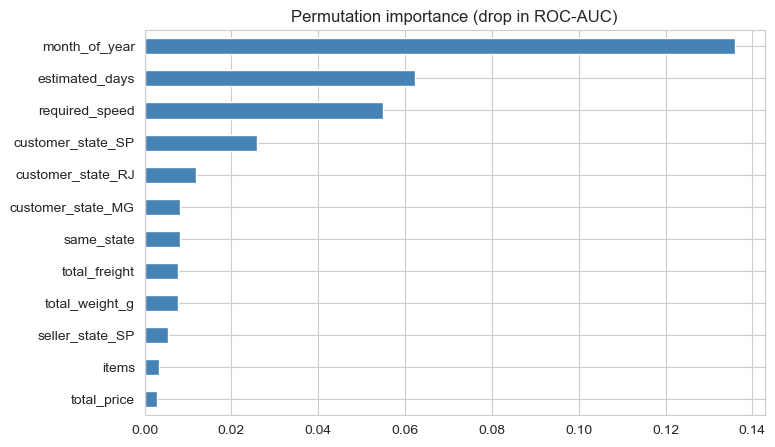

month_of_year        0.1360
estimated_days       0.0623
required_speed       0.0548
customer_state_SP    0.0259
customer_state_RJ    0.0118
customer_state_MG    0.0081
same_state           0.0081
total_freight        0.0078
total_weight_g       0.0076
seller_state_SP      0.0054
items                0.0032
total_price          0.0028
dtype: float64

In [37]:
X_perm = X_test_sel.sample(8000, random_state=1)
y_perm = y_test.loc[X_perm.index]

perm = permutation_importance(final, X_perm, y_perm, scoring='roc_auc', n_repeats=3, random_state=42, n_jobs=1)
perm_series = pd.Series(perm.importances_mean, index=selected).sort_values(ascending=False)

perm_series.head(12).sort_values().plot(kind='barh', figsize=(8, 5), color='steelblue')
plt.title('Permutation importance (drop in ROC-AUC)')
plt.show()

perm_series.head(12).round(4)

## Section 12: Honest check - does the model work on FUTURE orders?

**Concept box - why this matters.**
A random split mixes all months, so the model has seen orders from the same busy weeks it is tested on. In real life we predict **future** orders.
So we also train on the early months (up to Apr 2018) and test on the last months (May-Aug 2018). Scores are usually lower, and this lower number is the more honest one.
We also test the model **without** month features, because month_of_year can act as a label for one-off events.

**What:** Train and test Gradient Boosting in four ways: random split and time split, each with and without the month columns.
**Why:** Shows how much of the score comes from calendar/event information and how it holds up on future months.
**Watch out:** the late rate is lower in the future test months, so compare with their own baseline.

In [40]:
best_params = search.best_params_
month_cols = {'month_of_year', 'is_peak_season'}
no_month = list(set(selected) - month_cols)

train_time = (ml['purchase_month'] <= '2018-04')
test_time = (ml['purchase_month'] >= '2018-05')
print('Time split - train orders:', train_time.sum(), ' test orders:', test_time.sum())
print('Late % in train months:', round(y[train_time].mean() * 100, 2), ' in test months:', round(y[test_time].mean() * 100, 2))

m1 = HistGradientBoostingClassifier(**best_params, class_weight='balanced', random_state=42).fit(X_train[selected], y_train)
p1 = m1.predict_proba(X_test[selected])[:, 1]
m2 = HistGradientBoostingClassifier(**best_params, class_weight='balanced', random_state=42).fit(X_train[no_month], y_train)
p2 = m2.predict_proba(X_test[no_month])[:, 1]
m3 = HistGradientBoostingClassifier(**best_params, class_weight='balanced', random_state=42).fit(X.loc[train_time, selected], y[train_time])
p3 = m3.predict_proba(X.loc[test_time, selected])[:, 1]
m4 = HistGradientBoostingClassifier(**best_params, class_weight='balanced', random_state=42).fit(X.loc[train_time, no_month], y[train_time])
p4 = m4.predict_proba(X.loc[test_time, no_month])[:, 1]

check = pd.DataFrame({
    'roc_auc': [roc_auc_score(y_test, p1), roc_auc_score(y_test, p2), roc_auc_score(y[test_time], p3), roc_auc_score(y[test_time], p4)],
    'pr_auc': [average_precision_score(y_test, p1), average_precision_score(y_test, p2), average_precision_score(y[test_time], p3), average_precision_score(y[test_time], p4)],
    'random_guess_pr_auc': [y_test.mean(), y_test.mean(), y[test_time].mean(), y[test_time].mean()]
}, index=['Random split, with month', 'Random split, no month', 'Time split, with month', 'Time split, no month']).round(3)
check

Time split - train orders: 70716  test orders: 25080
Late % in train months: 7.61  in test months: 4.39


,roc_auc,pr_auc,random_guess_pr_auc
"Random split, with month",0.783,0.258,0.068
"Random split, no month",0.709,0.156,0.068
"Time split, with month",0.693,0.078,0.044
"Time split, no month",0.656,0.071,0.044


**What:** Chart of the four ROC-AUC scores.
**Why:** One picture of how much the score drops when we test on future months.
**Watch out:** 0.5 is a random guess.

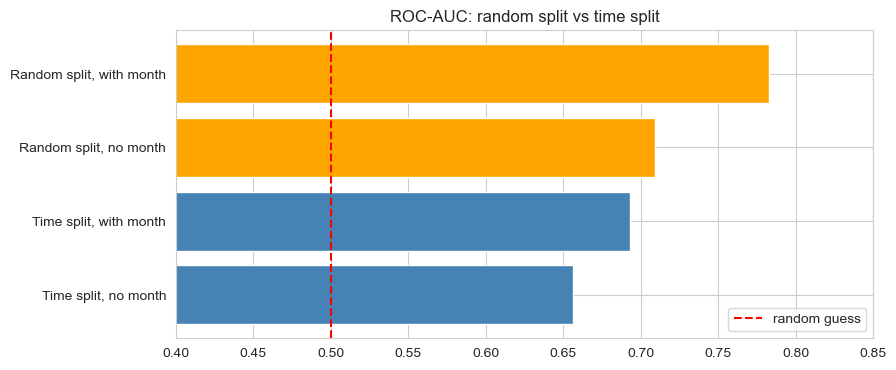

In [41]:
plt.figure(figsize=(9, 4))
plt.barh(check.index[::-1], check['roc_auc'].values[::-1], color=['steelblue', 'steelblue', 'orange', 'orange'])
plt.axvline(0.5, color='red', linestyle='--', label='random guess')
plt.xlim(0.4, 0.85)
plt.title('ROC-AUC: random split vs time split')
plt.legend()
plt.show()

## Section 13: Save the model and results

**What:** Save the final model, the list of selected features and the results table.
**Why:** So the model can be reused (for example in a small app) without retraining, and the results can go in your report.
**Watch out:** the model file only works with the same 30 columns in the same order.

In [42]:
joblib.dump(final, 'late_delivery_model.joblib')
pd.Series(selected).to_csv('selected_features.csv', index=False)
results_df.to_csv('model_results.csv')

print('Saved: late_delivery_model.joblib, selected_features.csv, model_results.csv')

Saved: late_delivery_model.joblib, selected_features.csv, model_results.csv


## Section 14: Conclusions

**Results on the test set (threshold 0.5, your numbers may differ slightly):**

| Model | Recall | Precision | ROC-AUC | PR-AUC |
|---|---|---|---|---|
| Dummy (never late) | 0.000 | 0.000 | 0.500 | 0.068 |
| Logistic Regression | 0.657 | 0.126 | 0.736 | 0.192 |
| Decision Tree | 0.648 | 0.150 | 0.745 | 0.195 |
| Random Forest | 0.544 | 0.196 | 0.779 | 0.251 |
| Gradient Boosting | 0.672 | 0.166 | 0.782 | 0.254 |
| Gradient Boosting (tuned) | 0.677 | 0.171 | 0.783 | 0.258 |

**1. The best model is the tuned Gradient Boosting** (Random Forest is almost as good). Its PR-AUC of 0.258 is about 3.8 times a random guess (0.068). The dummy model is 93% accurate but catches no late order, so accuracy is not a useful metric here.

**2. Cross-validation is stable.** The 5 fold scores of Gradient Boosting are close (ROC-AUC 0.771 to 0.788), so the result is not a lucky split.

**3. Feature selection worked.** 30 columns give almost the same score as all 70 (PR-AUC 0.254 vs 0.259).

**4. With the business rule "catch at least 60% of late orders"** the chosen threshold is about 0.54. On the test set this catches 812 of 1,297 late orders (recall 62.6%), flags 22.5% of orders, and about 19% of the flagged orders are really late (precision 18.8%), with 3,501 false alarms. The model is a **risk ranker**, not a crystal ball.

**5. Main drivers:** month of the year (events and peak season), the promised delivery days, the required speed (distance divided by promised days), destination state (SP, RJ, MG), same-state delivery, freight and weight. Price, items and payment matter very little.

**6. The honest check on future months is much weaker.** Training on months up to Apr 2018 and testing on May-Aug 2018 gives ROC-AUC 0.693 and PR-AUC 0.078 (random guess 0.044, so about 1.8 times better). Without the month columns, the random-split score falls from 0.783 to 0.709. This shows that part of the score comes from learning specific busy periods, which may not repeat. **The time-split number is the realistic expectation for real use.**

**Limitations**
- Only 2 years of data, so seasonality and one-off events (Black Friday 2017, early 2018 problems) cannot be separated.
- We have no data on carrier capacity, weather, strikes or public holidays, which probably explain a lot of the delay.
- Precision is low (about 1 in 5 alerts is a real late order), because late orders are rare.

**Possible next steps**
- Add a holiday calendar and each seller's past late rate (calculated only from earlier orders, to avoid leakage).
- Use time-based validation from the start and calibrate the probabilities.
- Try XGBoost or LightGBM (needs an extra install).
- Monitor the model over time, because delivery patterns change.

**How a business could use it:** flag the roughly 22% highest-risk orders at purchase time, so the company can show a safer promised date, warn the customer early, or push the seller and carrier to ship those orders first. From the SQL phase, adding 3 days to the promised date alone would cut the late rate from 6.77% to 4.83%.